# 4. Retracing, checkpoints and logging

[All tutorials](https://github.com/bateni1380/landpy/tree/master/tutorials) · [Open in Colab](https://colab.research.google.com/github/bateni1380/landpy/blob/master/tutorials/4-history-and-debugging.ipynb)

## Goal

Learn which history tool to use and inspect a flow with categorized textual and visual logs.

## Setup

Run every cell in order. Python 3.10+ is required; use Python 3.10–3.13 for TensorFlow examples. The first cell installs the pinned release if needed. A CPU is enough.

In [1]:
import importlib.metadata
import subprocess
import sys
try:
    installed = importlib.metadata.version('landpy')
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != '0.1.0':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'landpy==0.1.0'])
import numpy as np
import matplotlib.pyplot as plt
from landpy import ImageLand, MarksLand, SquareMarks, QuadMarks, DualMarks, HeatLand, Filter, Debugger
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.titlesize': 12})

## Steps

### 1. Retrace geometric operations

Pass `save_trace=True` to record an inverse. `retrace()` applies one inverse to the current data. Point geometry can round-trip accurately; image rotations and resizing lose information through resampling.

In [2]:
marks = MarksLand([[20, 30], [80, 120]], shape=(120, 180))
original = marks.get_marks().copy()
marks.move((12, -5), save_trace=True).rotate(25, save_trace=True)
marks.retrace().retrace()
np.testing.assert_allclose(marks.get_marks(), original, atol=1e-10)

### 2. Undo exact snapshots

Checkpoint **before** edits. Undo restores data and traces exactly; redo restores the edited state. A new operation after undo clears redo. `copy(copy_trace=True)` copies histories independently. Mutable array access is low-level: make a checkpoint before editing it and do not expect direct array writes to invalidate redo automatically.

In [3]:
rows, columns = np.indices((120, 180))
pixels = np.stack((columns / 179, rows / 119, np.full(rows.shape, .35)), axis=-1)
image = ImageLand(pixels)

original = image.get_image().copy()
image.make_checkpoint().rotate(27).reshape((80, 100))
edited = image.get_image().copy()
image.undo()
np.testing.assert_array_equal(image.get_image(), original)
image.redo()
np.testing.assert_array_equal(image.get_image(), edited)
print('Exact undo and redo passed.')

Exact undo and redo passed.


### 3. Observe nested operations

A Debugger can select class names, method names or qualified method names as categories. Timing scopes and decorator categories unwind even if a method raises. Logging defaults to off on data containers.

MarksLand.move started
  MarksLand.get_marks started (0.0000s)
    MarksLand.get_marks ended (0.0000s)
  MarksLand.move ended (0.0000s)
MarksLand.reshape started
  MarksLand.get_marks started (0.0000s)
    MarksLand.get_marks ended (0.0000s)
  MarksLand.reshape ended (0.0001s)
A small task started
  Task in progress (0.0000s)
  A small task ended (0.0000s)


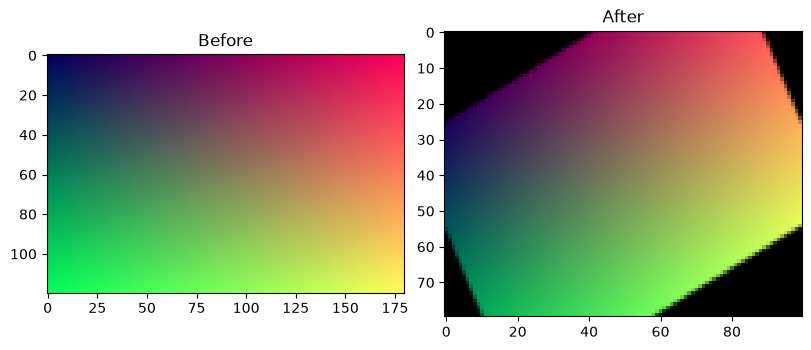

In [4]:
debugger = Debugger(textual_debug=True, categories=['MarksLand'])
marks.set_debugger(debugger).move((2, 3)).reshape((60, 90))
debugger.log_start('A small task')
debugger.log('Task in progress')
debugger.log_end()
visual = Debugger(visual_debug=True)
visual.save_image(original, 'Before')
visual.save_image(image.get_image(), 'After')
visual.log_saved_images();

## Checks

In [5]:
assert len(debugger._times) == 0
assert len(visual._images) == 0
image.undo().clear_checkpoint_history()
try:
    image.undo()
except IndexError as error:
    print(error)
help(ImageLand.rotate)

No checkpoint to undo.
Help on function rotate in module landpy.image_land:

rotate(self, angle, center=None, save_trace=False, fill_color=(0, 0, 0))
    Rotate counterclockwise in degrees; inverse resampling is approximate.



## Next steps

Continue with tutorial 5 in the [tutorial index](https://github.com/bateni1380/landpy/tree/master/tutorials).